# Exploratory data analysis: six visualizations

All EDA charts use the same 90-row course dataset. Associations are descriptive, with small group counts and time-dependent mission mix.

Executed reconstruction created for this report. These are not recovered copies of previously unshared learner notebooks.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, json
from IPython.display import display, Image, HTML
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data'
RESULTS = ROOT / 'results'
RESULTS.mkdir(exist_ok=True)


Matplotlib is building the font cache; this may take a moment.


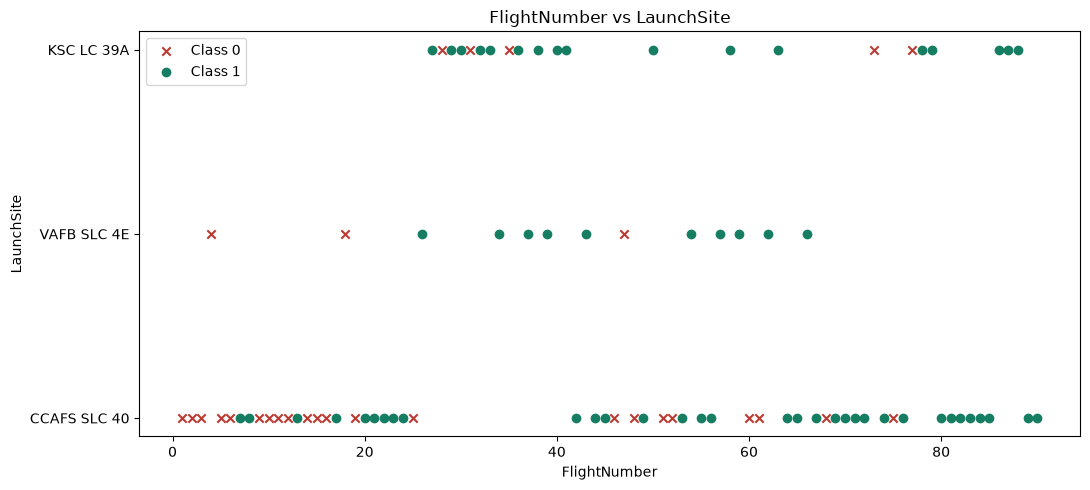

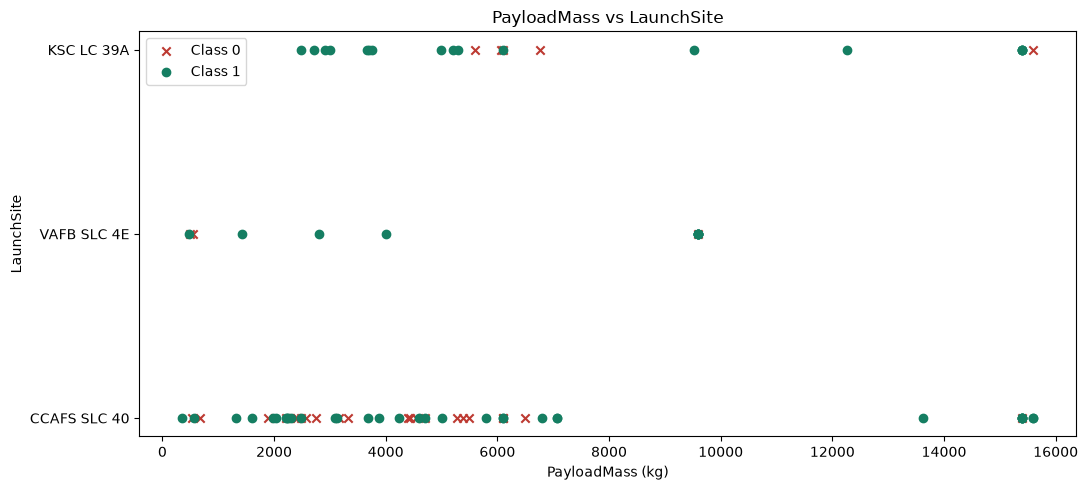

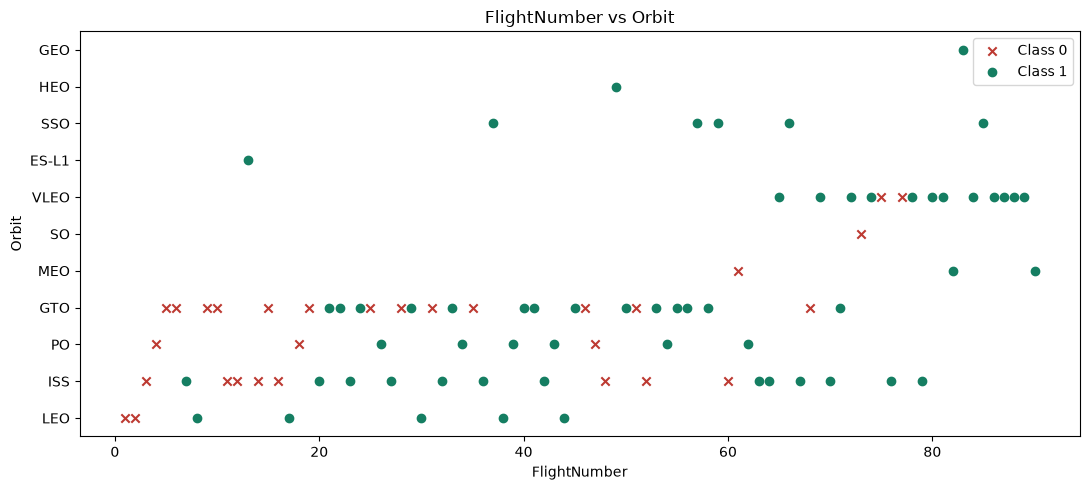

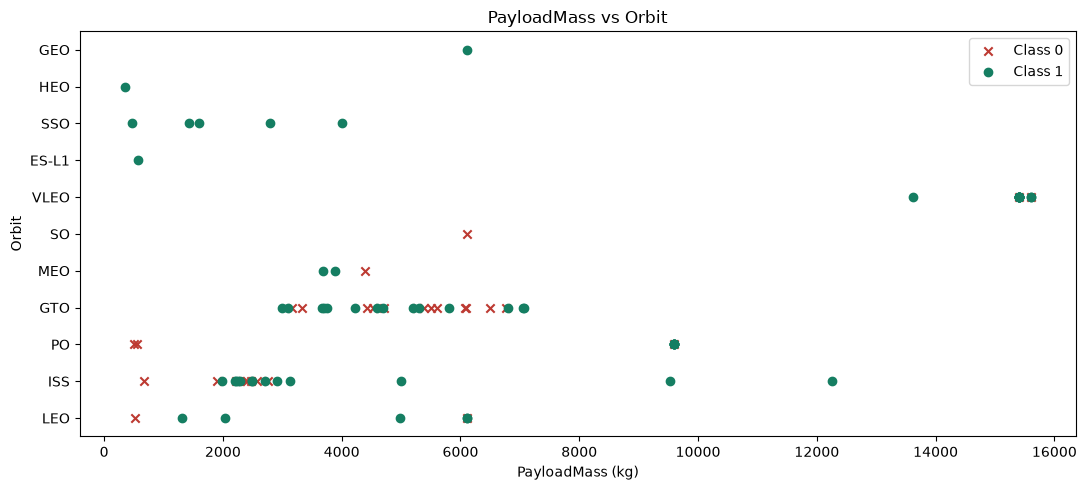

In [2]:
import matplotlib.pyplot as plt
df=pd.read_csv(DATA/'dataset_part_2.csv')
for x,y in [('FlightNumber','LaunchSite'),('PayloadMass','LaunchSite'),('FlightNumber','Orbit'),('PayloadMass','Orbit')]:
    fig,ax=plt.subplots(figsize=(11,5))
    for c,color,marker in [(0,'#bd3a32','x'),(1,'#157e62','o')]:
        d=df[df.Class==c];ax.scatter(d[x],d[y],label=f'Class {c}',c=color,marker=marker)
    ax.set(xlabel=x+' (kg)' if x=='PayloadMass' else x,ylabel=y,title=f'{x} vs {y}');ax.legend();fig.tight_layout();plt.show()

,sum,count,mean
Orbit,,,
ES-L1,1,1,1.000000
GEO,1,1,1.000000
GTO,14,27,0.518519
HEO,1,1,1.000000
ISS,13,21,0.619048
LEO,5,7,0.714286
MEO,2,3,0.666667
PO,6,9,0.666667
SO,0,1,0.000000


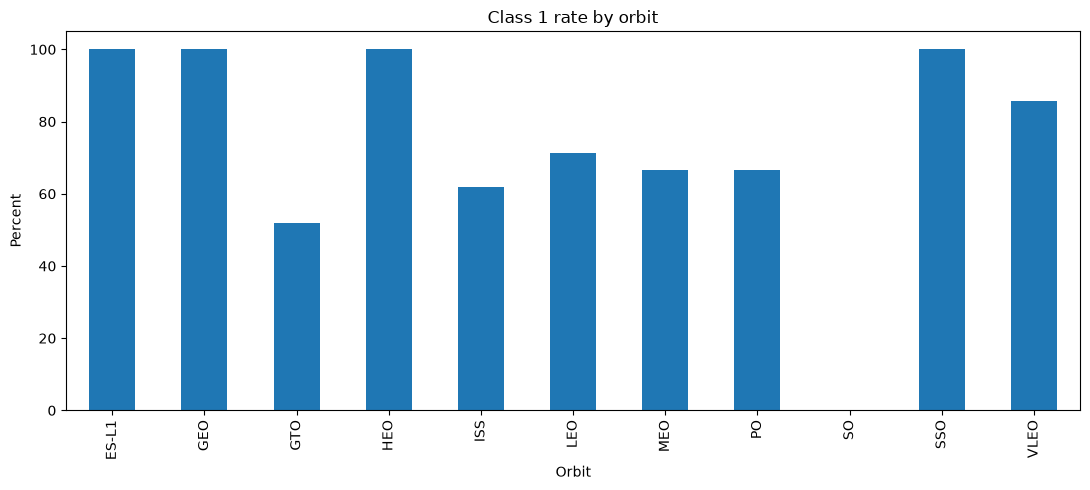

,sum,count,mean
Year,,,
2010,0,1,0.000000
2012,0,1,0.000000
2013,0,3,0.000000
2014,2,6,0.333333
2015,2,6,0.333333
2016,5,8,0.625000
2017,15,18,0.833333
2018,11,18,0.611111
2019,9,10,0.900000


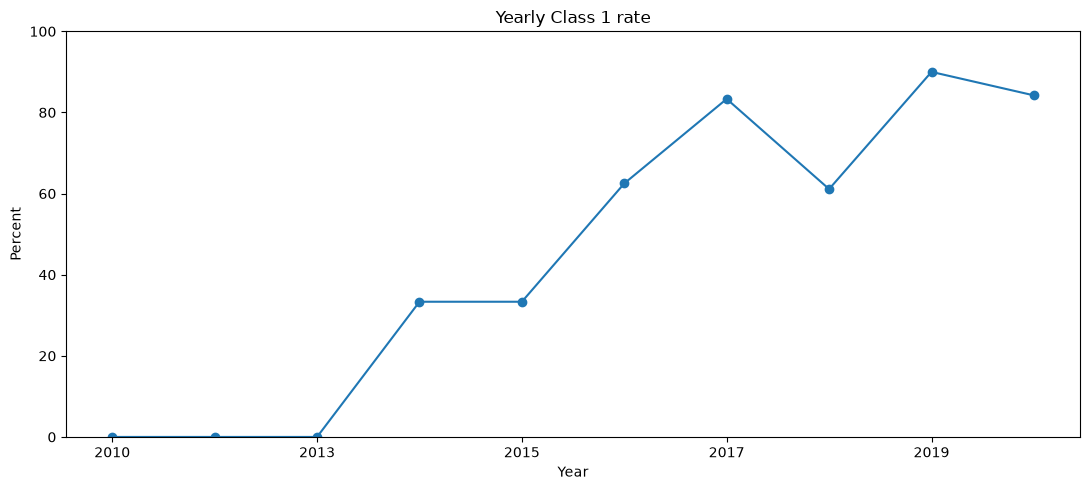

In [3]:
orbit=df.groupby('Orbit').Class.agg(['sum','count','mean']);display(orbit)
ax=(orbit['mean']*100).plot.bar(figsize=(11,5),title='Class 1 rate by orbit',ylabel='Percent');plt.tight_layout();plt.show()
year=df.assign(Year=df.Date.str[:4]).groupby('Year').Class.agg(['sum','count','mean']);display(year)
(year['mean']*100).plot(marker='o',figsize=(11,5),ylim=(0,100),ylabel='Percent',title='Yearly Class 1 rate');plt.tight_layout();plt.show()